# PeakPehle - dataset exploration (SYNTHETIC data)

This notebook explores the synthetic demo dataset: coverage, quality alerts, meter hierarchy, daily profile, the 4-8 PM window and the forecast baseline. **Nothing here is MITS data.** For real method testing, the brief names Building Data Genome Project 2 and ASHRAE GEP III (check licences before reuse).

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, matplotlib.pyplot as plt
from peakpehle import data_io, forecast
readings = data_io.load_readings('../data/synthetic_readings.csv')
meter_map = pd.read_csv('../data/meter_map.csv')
readings.groupby('meter_id')['value'].describe()

,count,mean,std,min,25%,50%,75%,max
meter_id,,,,,,,,
MAIN,1344.0,233.358110,91.095709,127.1,151.4,214.0,308.625,506.7
SUB_ACAD,1344.0,104.198586,73.730744,41.3,57.7,62.6,204.150,249.1
SUB_HOSTEL,1344.0,81.629836,44.997911,34.3,48.8,54.1,138.400,175.9


In [2]:
rep = data_io.check_quality(readings, meter_map)
pd.DataFrame(rep.alerts), rep.coverage

(  severity meter               kind  \
 0    block  MAIN  hierarchy_overlap   
 
                                               detail  
 0  parent and sub-meters ['SUB_ACAD', 'SUB_HOSTEL...  ,
 {'MAIN': 1.0, 'SUB_ACAD': 1.0, 'SUB_HOSTEL': 1.0})

In [3]:
bad = data_io.load_readings('../data/defective_readings.csv')
pd.DataFrame(data_io.check_quality(bad).alerts)

,severity,meter,kind,detail
0,warn,MAIN,duplicate_timestamps,2 duplicate rows
1,warn,MAIN,missing_intervals,60 missing (4.5%)
2,block,MAIN,invalid_values,"1 negative, missing or > 5000 kW"


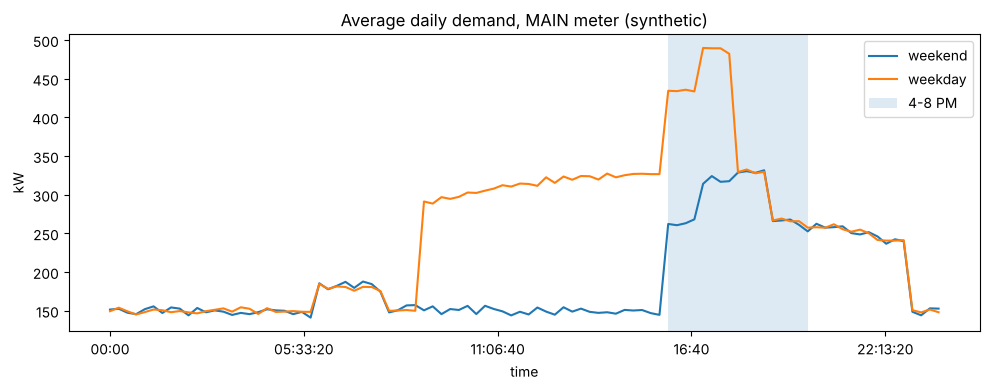

In [4]:
main = readings[readings.meter_id=='MAIN'].set_index('timestamp')['value']
profile = main.groupby([main.index.dayofweek < 5, main.index.time]).mean().unstack(0)
profile.columns = ['weekend', 'weekday']
ax = profile.plot(figsize=(10,4), title='Average daily demand, MAIN meter (synthetic)')
ax.axvspan(16*3600, 20*3600, alpha=0.15, label='4-8 PM')
ax.set_ylabel('kW'); ax.legend(); plt.tight_layout(); plt.savefig('../docs/daily_profile.png', dpi=120)

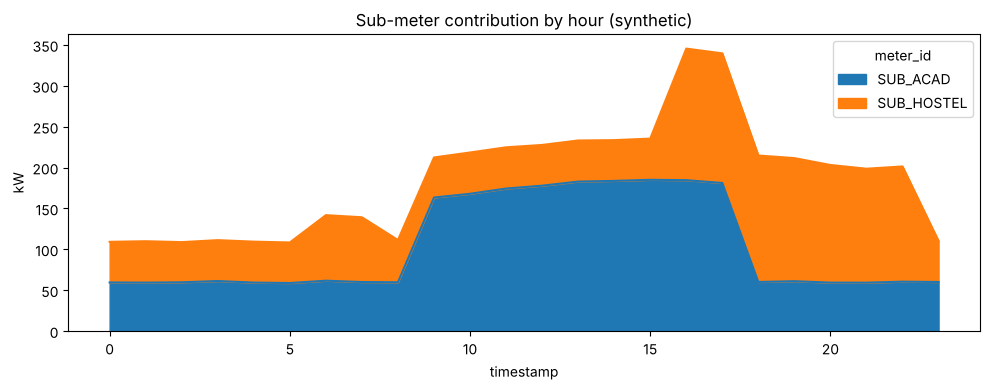

In [5]:
subs = readings[readings.meter_id!='MAIN'].pivot(index='timestamp', columns='meter_id', values='value')
share = subs.groupby(subs.index.hour).mean()
share.plot.area(figsize=(10,4), title='Sub-meter contribution by hour (synthetic)'); plt.ylabel('kW'); plt.tight_layout()

In [6]:
forecast.evaluate(main)

{'weekly_seasonal_naive': {'MAE': 9.6, 'RMSE': 12.3, 'evening_MAE': 8.2},
 'daily_naive': {'MAE': 28.8, 'RMSE': 59.7, 'evening_MAE': 37.0},
 'decision': "keep 'weekly_seasonal_naive' as baseline; add a complex model only if it beats this"}

**Reading:** in this synthetic set the weekday peak sits at about 17:00, driven by academic and hostel loads overlapping, plus evening pumping. The weekly seasonal-naive forecast beats the daily-naive one, so it stays the baseline. A real dataset could show something different; this notebook only shows the method.